# Phase 4 | Regression, correlation and model diagnostics

Among eligible participants with normal cognition, how does mean animal-naming performance vary with left inferior parietal thickness after accounting for age, recorded sex and education?

The notebook rebuilds the registered analysis in memory, checks the saved results and displays aggregate tables and unlabeled plots. Execute it after the preceding steps in the [README](../README.md).

In [1]:
import os
from io import BytesIO
from pathlib import Path
from IPython.display import Image, Markdown, display

root = next(path for path in (Path.cwd(), *Path.cwd().parents)
            if (path / "src" / "phase4_review.py").is_file())
os.chdir(root)

from src.phase4_review import audit_analysis, figure_groups, requirement_coverage
from src.phase4_tables import MODEL_LABELS, coefficient_rows
from src.phase1_figures import plt

results, context, figure_paths = audit_analysis()

def show_table(headers, rows):
    lines = ["| " + " | ".join(headers) + " |", "|" + "---|" * len(headers)]
    lines.extend("| " + " | ".join(map(str, row)) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

labels = {'sample_header': ['Sample step', 'Participants'], 'sample_steps': ['Matched UDS and MRI', 'Normal cognition before exclusions', 'Usable matched score and thickness', 'Common modeling sample'], 'design': ['Model', 'Columns', 'Residual df'], 'correlation': ['Pearson r', 'Simple R²', 'Nominal two-sided p'], 'classical': 'Model-based', 'coefficients': ['Term', 'Estimate', 'SE', 't', 'Two-sided p', 'Individual 95% interval'], 'underflow': 'Underflow', 'fit': ['Model', 'n', 'df', 'SSE', 'R²', 'Adjusted R²', 'Residual SD', 'In-sample RMSE'], 'dependence': 'Predictor correlations and VIF', 'term': 'Term', 'rank': 'Rank', 'condition': 'Standardized condition number', 'identity': ['Covariate', 'Contribution to marginal minus adjusted slope'], 'flags': ['Model', 'Residual', 'Leverage', 'Cook', 'Union'], 'omission': ['Diagnostic fit', 'n per fit', 'Thickness estimate or range'], 'loo': 'Single omission', 'joint': 'Joint omission', 'prediction': ['Nominal 95% target', 'Point', 'SE or prediction SD', 'Interval', 'Width'], 'targets': ['Conditional mean', 'New individual score'], 'coverage': ['Requirement', 'Coverage', 'Report sections'], 'addressed': 'Addressed', 'partially_verifiable': 'Partial, timing metadata unavailable'}

## 1. Common sample and coding

Each model uses the same 842 people and response order. ANIMALS counts correct animal names in 60 seconds and takes usable integer values from 0 to 77. Thickness is continuous, with a coefficient per 0.1 mm. Age and education are centered and measured in years. Recorded sex is coded zero for male and one for female. The supplied records match one-to-one. Their measurement dates are unavailable.

In [2]:
plan = results["plan"]
sample = plan["sample"]["counts"]
show_table(labels["sample_header"], zip(labels["sample_steps"], (
    sample["matched"], sample["normal_before_filters"],
    sample["paired_normal"], sample["model_normal"],
)))
show_table(labels["design"], [
    (MODEL_LABELS[name], ", ".join(spec["columns"]), context["fits"][name].residual_df)
    for name, spec in plan["models"].items()
])

| Sample step | Participants |
|---|---|
| Matched UDS and MRI | 1237 |
| Normal cognition before exclusions | 847 |
| Usable matched score and thickness | 843 |
| Common modeling sample | 842 |

| Model | Columns | Residual df |
|---|---|---|
| UDS-only | intercept, age_c, female, education_c | 838 |
| MRI-only | intercept, thickness_0_1mm | 840 |
| UDS + MRI | intercept, thickness_0_1mm, age_c, female, education_c | 837 |

## 2. Simple and multiple regression

The MRI-only slope summarizes the unadjusted mean-score difference. Its R² equals the square of Pearson's r. The classical zero-slope and Pearson tests give the same p-value on these observations.

Multiple regression coefficients compare participants at fixed values of other terms. The combined thickness coefficient is the registered primary comparison at a two-sided 0.05 level. HC3 supplies companion coefficient uncertainty.

In [3]:
simple = results["simple"]
multiple = results["multiple"]
r = simple["correlation"]
show_table(labels["correlation"], [(f"{r['coefficient']:.6f}", f"{simple['fit']['R_squared']:.6f}",
                                   f"{r['p_value_two_sided_nominal']:.6f}")])
for name, model in (("mri_only", simple), *multiple["models"].items()):
    for key, method in (("model_based", labels["classical"]), ("hc3", "HC3")):
        display(Markdown(f"**{MODEL_LABELS[name]} · {method} · df = {model['fit']['residual_df']}**"))
        show_table(labels["coefficients"], [
            (term, f"{beta:.5f}", f"{se:.5f}", f"{stat:.5f}",
             labels["underflow"] if underflow else f"{p:.6g}", f"[{lo:.5f}, {hi:.5f}]")
            for term, beta, se, stat, p, lo, hi, underflow in coefficient_rows(model, key)
        ])

| Pearson r | Simple R² | Nominal two-sided p |
|---|---|---|
| 0.018115 | 0.000328 | 0.599652 |

**MRI-only · Model-based · df = 840**

| Term | Estimate | SE | t | Two-sided p | Individual 95% interval |
|---|---|---|---|---|---|
| Intercept | 22.33761 | 0.18761 | 119.06301 | Underflow | [21.96937, 22.70586] |
| Thickness | 0.08098 | 0.15423 | 0.52510 | 0.599652 | [-0.22173, 0.38370] |

**MRI-only · HC3 · df = 840**

| Term | Estimate | SE | t | Two-sided p | Individual 95% interval |
|---|---|---|---|---|---|
| Intercept | 22.33761 | 0.18844 | 118.54000 | Underflow | [21.96775, 22.70748] |
| Thickness | 0.08098 | 0.15425 | 0.52502 | 0.599707 | [-0.22178, 0.38375] |

**UDS-only · Model-based · df = 838**

... (3 outputs left out)

**UDS + MRI · Model-based · df = 837**

| Term | Estimate | SE | t | Two-sided p | Individual 95% interval |
|---|---|---|---|---|---|
| Intercept | 22.06945 | 0.30433 | 72.51929 | Underflow | [21.47212, 22.66679] |
| Thickness | -0.12570 | 0.15078 | -0.83372 | 0.404677 | [-0.42165, 0.17024] |
| Age | -0.14229 | 0.02278 | -6.24691 | 6.65644e-10 | [-0.18699, -0.09758] |
| Recorded sex | -0.14241 | 0.37450 | -0.38028 | 0.703836 | [-0.87748, 0.59265] |
| Education | 0.60324 | 0.06830 | 8.83195 | 5.95577e-18 | [0.46918, 0.73731] |

**UDS + MRI · HC3 · df = 837**

| Term | Estimate | SE | t | Two-sided p | Individual 95% interval |
|---|---|---|---|---|---|
| Intercept | 22.06945 | 0.29532 | 74.73070 | Underflow | [21.48980, 22.64911] |
| Thickness | -0.12570 | 0.14523 | -0.86554 | 0.38699 | [-0.41077, 0.15936] |
| Age | -0.14229 | 0.02480 | -5.73714 | 1.34526e-08 | [-0.19097, -0.09361] |
| Recorded sex | -0.14241 | 0.36898 | -0.38597 | 0.69962 | [-0.86664, 0.58182] |
| Education | 0.60324 | 0.06386 | 9.44629 | 3.40506e-20 | [0.47790, 0.72859] |

## 3. Fit comparison and collinearity

Adding thickness to the UDS baseline changes in-sample fit slightly. Adjusted R² decreases after accounting for one extra parameter. Weighted demographic terms explain the change in the thickness coefficient algebraically. Full rank and low VIFs indicate limited linear dependence among these predictors.

In [4]:
comparison = results["comparison"]
show_table(labels["fit"], [
    (MODEL_LABELS[name], fit["participants"], fit["residual_df"], f"{fit['SSE']:.3f}",
     f"{fit['R_squared']:.6f}", f"{fit['adjusted_R_squared']:.6f}",
     f"{fit['residual_SD']:.5f}", f"{fit['in_sample_RMSE']:.5f}")
    for name, fit in comparison["fit_comparison"].items()
])
for name, item in comparison["collinearity"].items():
    terms = item["predictor_order"]
    display(Markdown(f"**{MODEL_LABELS[name]} · {labels['dependence']}**"))
    show_table([labels["term"], *terms, "VIF"], [
        (term, *(f"{v:.5f}" for v in row), f"{item['vif'][term]['VIF']:.5f}")
        for term, row in zip(terms, item["correlation_matrix"])
    ])
    print(labels["rank"], item["rank"], "|", labels["condition"],
          f"{item['standardized_design_condition_number']:.5f}")
show_table(labels["identity"], [
    (term, f"{item['contribution_to_marginal_minus_adjusted']:.6f}")
    for term, item in comparison["thickness_change_identity"]["components"].items()
])

| Model | n | df | SSE | R² | Adjusted R² | Residual SD | In-sample RMSE |
|---|---|---|---|---|---|---|---|
| UDS-only | 842 | 838 | 21686.354 | 0.125640 | 0.122510 | 5.08711 | 5.07501 |
| MRI-only | 842 | 840 | 24794.413 | 0.000328 | -0.000862 | 5.43297 | 5.42651 |
| UDS + MRI | 842 | 837 | 21668.359 | 0.126366 | 0.122191 | 5.08804 | 5.07291 |

**UDS-only · Predictor correlations and VIF**

| Term | age_c | female | education_c | VIF |
|---|---|---|---|---|
| age_c | 1.00000 | -0.06146 | -0.01728 | 1.00436 |
| female | -0.06146 | 1.00000 | -0.10212 | 1.01464 |
| education_c | -0.01728 | -0.10212 | 1.00000 | 1.01111 |

Rank 4 | Standardized condition number 1.12887


**UDS + MRI · Predictor correlations and VIF**

| Term | thickness_0_1mm | age_c | female | education_c | VIF |
|---|---|---|---|---|---|
| thickness_0_1mm | 1.00000 | -0.23787 | 0.17452 | -0.00358 | 1.08971 |
| age_c | -0.23787 | 1.00000 | -0.06146 | -0.01728 | 1.06090 |
| female | 0.17452 | -0.06146 | 1.00000 | -0.10212 | 1.04304 |
| education_c | -0.00358 | -0.01728 | -0.10212 | 1.00000 | 1.01120 |

Rank 5 | Standardized condition number 1.35077


| Covariate | Contribution to marginal minus adjusted slope |
|---|---|
| age_c | 0.221066 |
| female | -0.009790 |
| education_c | -0.004588 |

## 4. Grayscale figures and influence

The figures show the simple fit and common coefficients before the residual diagnostics. Q-Q departures are clearest in the tails and residual spread varies. Review flags use strict thresholds of 3 for absolute internally studentized residuals, 2p/n for leverage and 4/n for Cook's distance. Diagnostic omission intervals describe sensitivity after selection. The primary fit uses all eligible observations.

| Model | Residual | Leverage | Cook | Union |
|---|---|---|---|---|
| UDS-only | 5 | 39 | 34 | 65 |
| MRI-only | 4 | 57 | 43 | 81 |
| UDS + MRI | 5 | 45 | 37 | 70 |

| Diagnostic fit | n per fit | Thickness estimate or range |
|---|---|---|
| Single omission | 841 | [-0.15084, -0.08599] |
| Joint omission | 772 | -0.05327 |

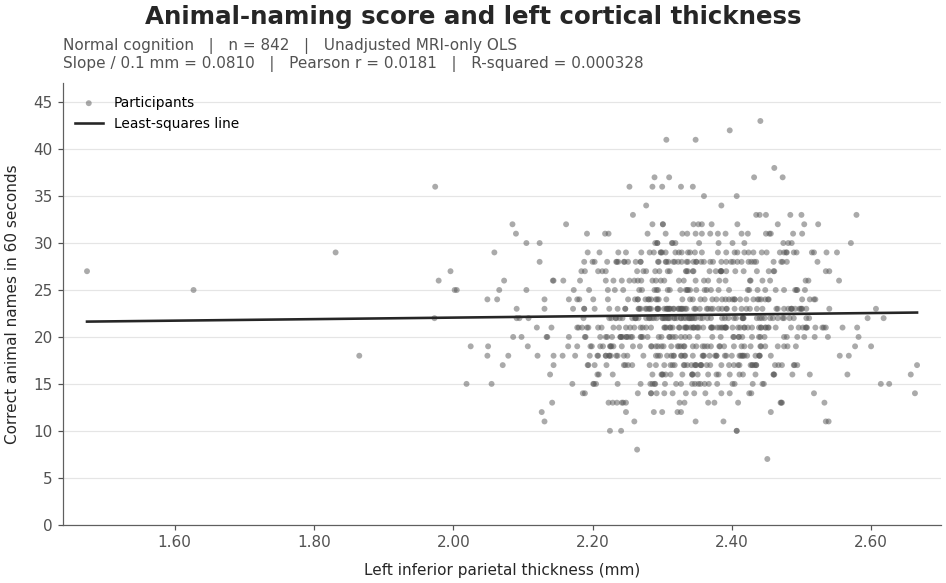

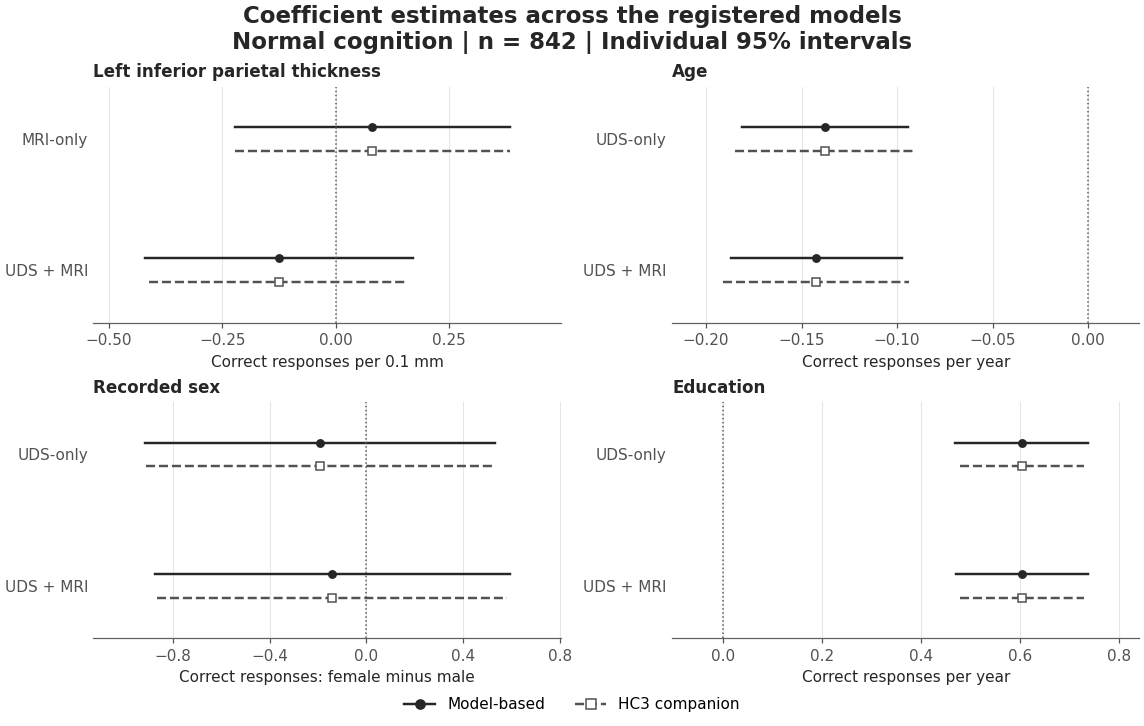

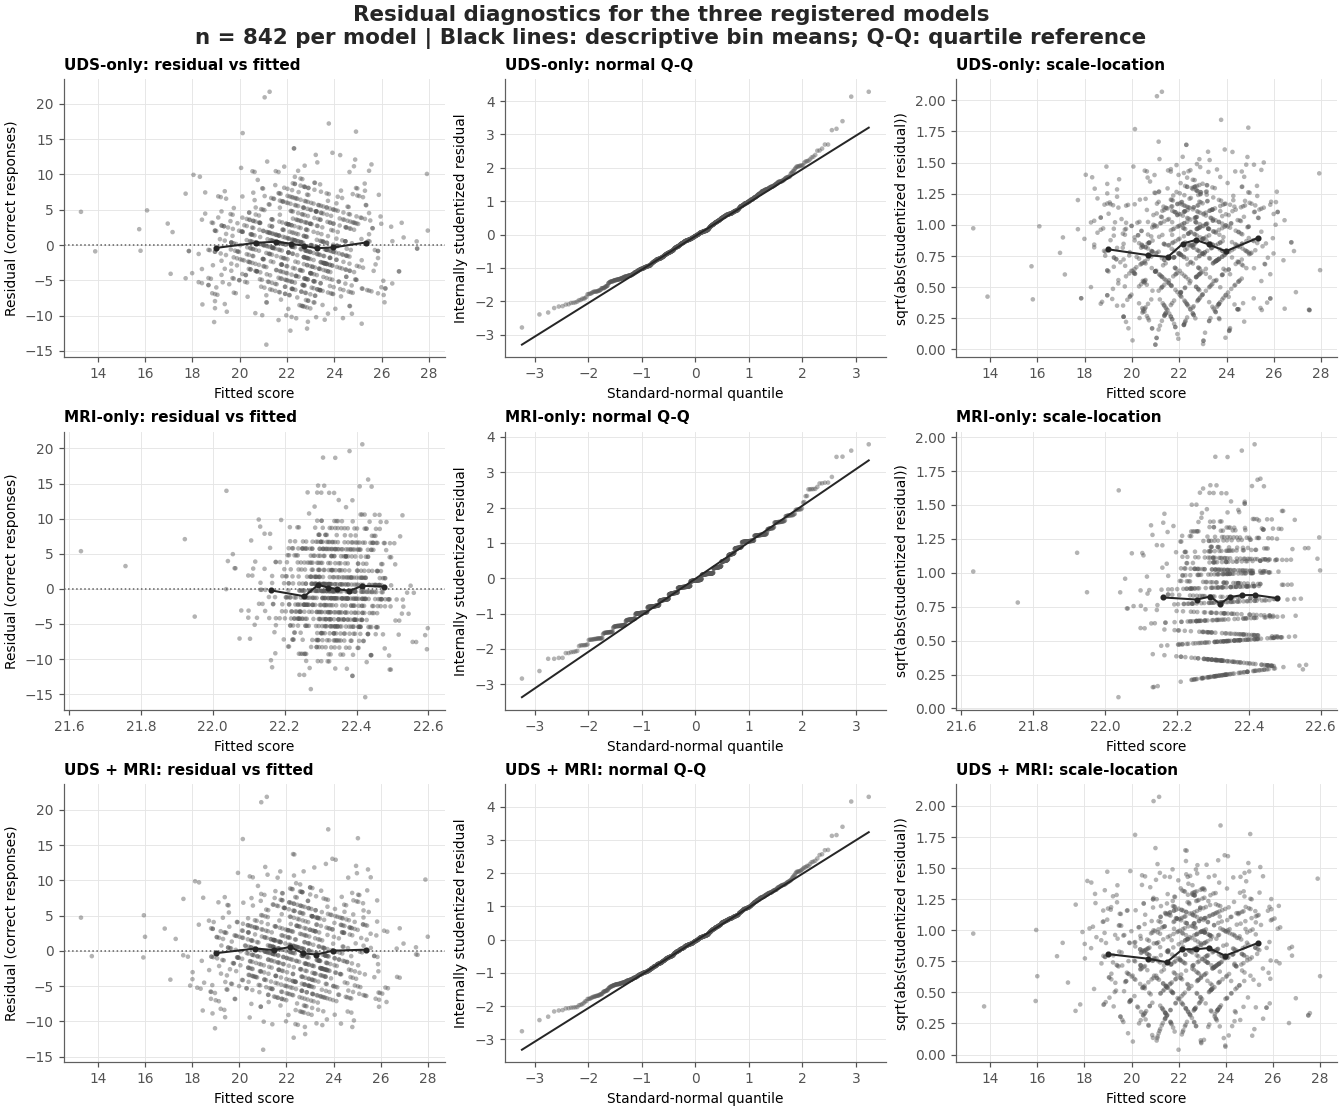

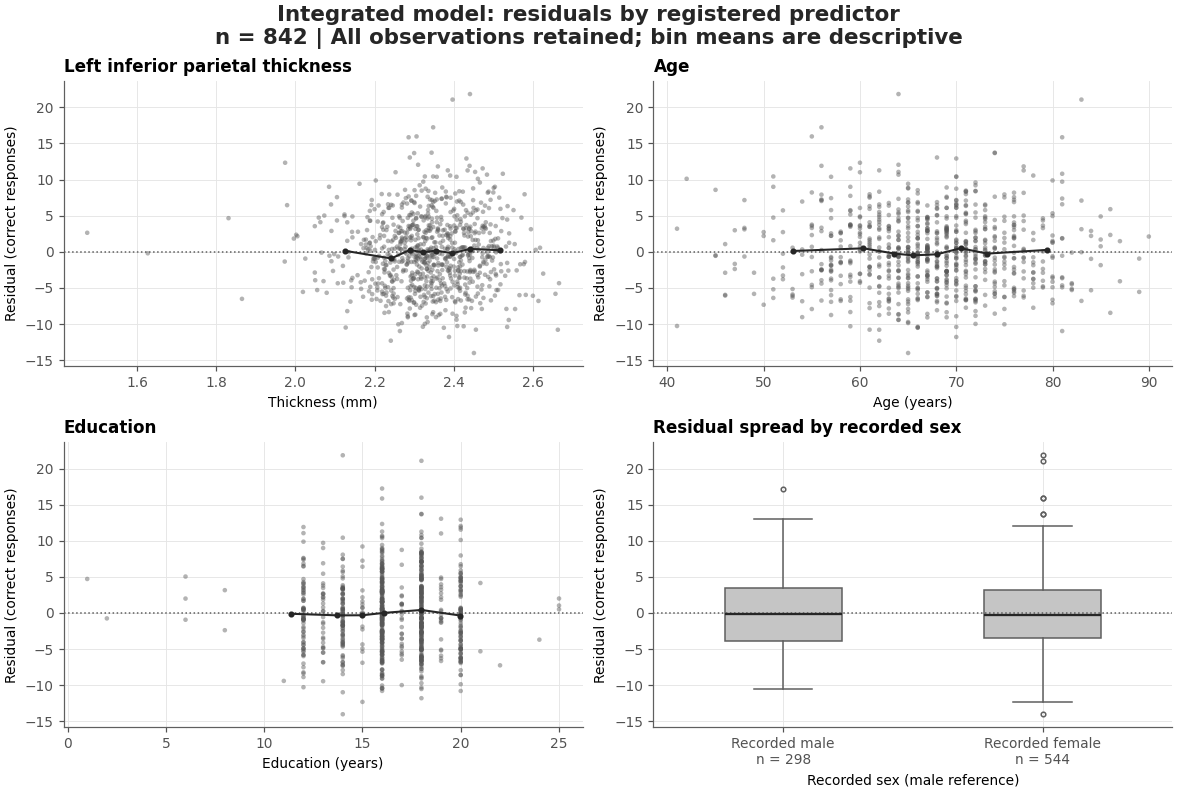

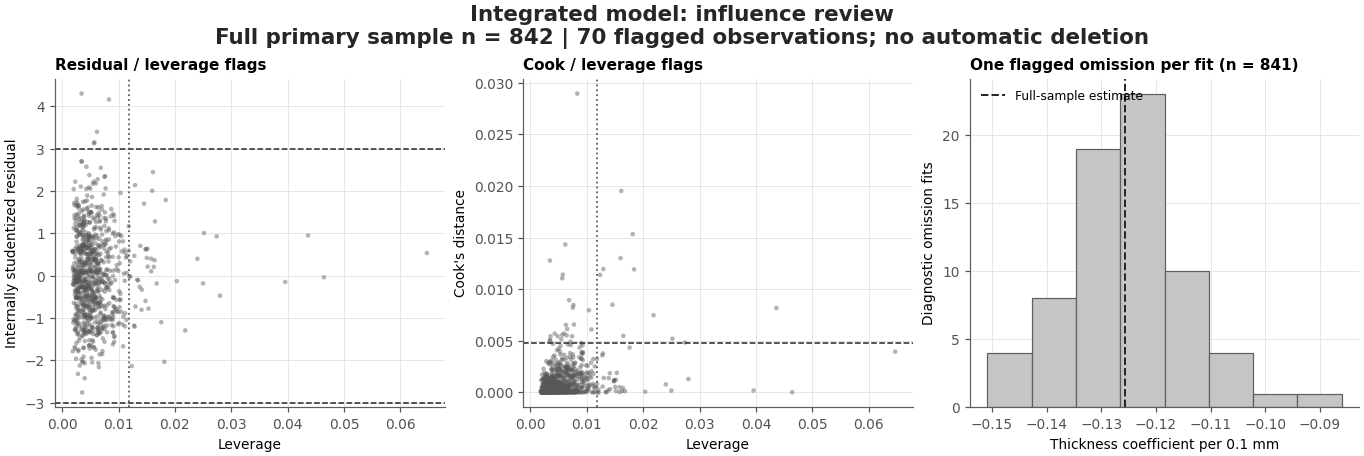

In [5]:
diagnostics = results["diagnostic"]
show_table(labels["flags"], [
    (MODEL_LABELS[name], flags["counts"]["studentized"], flags["counts"]["leverage"],
     flags["counts"]["cooks_distance"], flags["union_count"])
    for name, detail in diagnostics["models"].items() for flags in [detail["review_flags"]]
])
sensitivity = diagnostics["integrated_influence_followup"]
loo = sensitivity["individual_leave_one_out"]["estimate"]
joint = sensitivity["joint_union_omission"]
show_table(labels["omission"], [
    (labels["loo"], 841, f"[{loo['minimum']:.5f}, {loo['maximum']:.5f}]"),
    (labels["joint"], joint["retained"], f"{joint['thickness']['estimate']:.5f}"),
])
for group in figure_groups(results, context):
    for path, figure in group:
        try:
            with BytesIO() as buffer:
                figure.savefig(buffer, format="png", dpi=110)
                display(Image(data=buffer.getvalue()))
        finally:
            plt.close(figure)

## 5. Model decision and fixed-profile intervals

The central predictor plots provide insufficient evidence to add a quadratic thickness term. The retained model uses the original score units. Residual spread and tail departures qualify the classical intervals.

The registered profile is a recorded male aged 68 with 16 years of education and left thickness of 2.344 mm. The mean interval describes uncertainty in the conditional mean. The individual interval also includes residual variation for one new independent eligible participant with the same profile.

In [6]:
q = results["prediction"]["intervals"]
show_table(labels["prediction"], [
    (label, f"{q['point_estimate']:.5f}", f"{entry['standard_error']:.5f}",
     f"[{entry['lower']:.5f}, {entry['upper']:.5f}]", f"{entry['width']:.5f}")
    for label, entry in zip(labels["targets"], (q["mean_confidence_interval"], q["individual_prediction_interval"]))
])
show_table(labels["coverage"], [
    (key, labels[item["status"]], ", ".join(item["sections"]))
    for key, item in requirement_coverage(plan).items()
])

| Nominal 95% target | Point | SE or prediction SD | Interval | Width |
|---|---|---|---|---|
| Conditional mean | 22.06945 | 0.30433 | [21.47212, 22.66679] | 1.19466 |
| New individual score | 22.06945 | 5.09713 | [12.06480, 32.07411] | 20.00932 |

| Requirement | Coverage | Report sections |
|---|---|---|
| general_1 | Addressed | design |
| general_2 | Addressed | simple |
| general_3 | Addressed | simple |
| general_4 | Addressed | multiple |
| general_5 | Addressed | compare |
| general_6 | Addressed | design, multiple |
| general_7 | Addressed | diagnostics |
| general_8 | Addressed | profile |
| general_9 | Addressed | profile |
| general_10 | Addressed | simple |
| general_11 | Addressed | compare |
| track_c1 | Addressed | design |
| track_c2 | Addressed | design, multiple |
| track_c3 | Addressed | simple, diagnostics |
| track_c4 | Addressed | multiple, compare |
| track_c5 | Partial, timing metadata unavailable | design |
| track_c6 | Addressed | diagnostics |

## Interpretation and files

The adjusted estimate is about -0.126 correct responses per 0.1 mm, with a model-based 95% interval of roughly -0.422 to 0.170 and p = 0.405. The direction remains uncertain. Unknown preparation, the sampling frame and missing visit timing limit generalization. The fixed-profile intervals are model-based approximations.

[Phase 4 report](../reports/phase4.pdf) · [Final review](../reports/phase4/regression_review.json) · [Course guide](../docs/amarpr.pdf)